<a href="https://colab.research.google.com/github/melissa-04/spink1-gbm-hypoxia/blob/main/07_survival.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 07 Survival analysis

Tests the association between SPINK1 expression and overall survival in the three IDH-wildtype glioblastoma cohorts and, as a reference, in all primary gliomas of the two CGGA cohorts. Table S11a repeats the TCGA analysis of the original submission (n = 98, hazard ratio per log2 unit). Tables S11b-c and Figure S1 add Cox models with hazard ratios per 1 SD, Kaplan-Meier analysis by SPINK1 group and a scan of all cut-offs that leave at least 20% of patients in each group.

In [2]:
%%capture
!pip install -q gseapy lifelines

In [3]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys, zipfile
import numpy as np
import pandas as pd
from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.statistics import logrank_test, multivariate_logrank_test, proportional_hazard_test

BASE = '/content/drive/MyDrive/SPINK1'
REPO = os.path.join(BASE, 'repo')
RESULTS = os.path.join(REPO, 'results')
sys.path.append(REPO)
from spink1_utils import (MYELOID, MES_CLEAN, GROUP_ORDER, hallmark_sets, proliferation_genes,
                          panel_score, spink1_groups)

Mounted at /content/drive


In [4]:
coh = pd.read_csv(os.path.join(RESULTS, 'Table_S1_cohort.csv')).set_index('SAMPLE_ID')
L = pd.read_parquet(os.path.join(REPO, 'processed', 'tcga_expression.parquet'))
lib = hallmark_sets()

tcga = pd.DataFrame({
    'SPINK1': coh['SPINK1_log2'], 'group': coh['SPINK1_group'],
    'time': pd.to_numeric(coh['OS_MONTHS'], errors='coerce'),
    'event': coh['OS_STATUS'].astype(str).str.startswith('1').astype(int),
    'age': coh['AGE'], 'male': coh['SEX'].map({'Male': 1.0, 'Female': 0.0}),
    'buffa': coh['BUFFA_HYPOXIA_SCORE'],
    'myeloid': panel_score(L, MYELOID),
    'mes_clean': panel_score(L, MES_CLEAN),
    'proliferation': panel_score(L, proliferation_genes(lib))})
tcga = tcga[tcga['time'] > 0]

In [5]:
MODELS = {'SPINK1 alone': [],
          '+ age, sex': ['age', 'male'],
          '+ hypoxia': ['age', 'male', 'buffa'],
          '+ full': ['age', 'male', 'buffa', 'myeloid', 'mes_clean', 'proliferation']}

rows = []
for name, covariates in MODELS.items():
    d = tcga.loc[tcga['age'].notna(), ['SPINK1', *covariates, 'time', 'event']].dropna()
    s = CoxPHFitter().fit(d, 'time', 'event').summary.loc['SPINK1']
    rows.append({'model': name, 'n': len(d), 'HR_per_log2': round(s['exp(coef)'], 3),
                 'CI95': f"[{s['exp(coef) lower 95%']:.2f}, {s['exp(coef) upper 95%']:.2f}]",
                 'p': f"{s['p']:.4f}"})

s11a = pd.DataFrame(rows)
s11a.to_csv(os.path.join(RESULTS, 'Table_S11a_survival_TCGA.csv'), index=False)
print(s11a.to_string(index=False))

       model  n  HR_per_log2         CI95      p
SPINK1 alone 98        1.002 [0.87, 1.15] 0.9785
  + age, sex 98        1.024 [0.89, 1.17] 0.7294
   + hypoxia 98        1.002 [0.86, 1.16] 0.9819
      + full 98        0.946 [0.77, 1.17] 0.6038


In [6]:
def extract(name):
    with zipfile.ZipFile(os.path.join(BASE, name)) as z:
        member = [m for m in z.namelist() if m.endswith('.txt') and not m.startswith('__MACOSX')][0]
        return z.extract(member, '/content/cgga')

def spink1_log2cpm(counts, ids):
    m = counts[ids].apply(pd.to_numeric, errors='coerce')
    m['mean_count'] = m.mean(axis=1)
    m = m.sort_values('mean_count', ascending=False)
    m = m[~m.index.duplicated()].drop(columns='mean_count')
    return np.log2(m.loc['SPINK1'] / m.sum() * 1e6 + 1)

gbm, glioma = [], []
for tag in ['693', '325']:
    clin = pd.read_csv(extract(f'CGGA.mRNAseq_{tag}_clinical.20200506.txt.zip'), sep='\t')
    clin.columns = clin.columns.str.strip()
    raw = pd.read_csv(extract(f'CGGA.mRNAseq_{tag}.Read_Counts-genes.20220620.txt.zip'), sep='\t', low_memory=False)
    counts = raw[raw.iloc[:, 0].notna()].set_index(raw.columns[0])
    clin = clin[clin['CGGA_ID'].isin(counts.columns)].set_index('CGGA_ID')

    d = pd.DataFrame({'cohort': f'CGGA-{tag}',
                      'time': pd.to_numeric(clin['OS'], errors='coerce') / 30.44,
                      'event': clin['Censor (alive=0; dead=1)'],
                      'age': clin['Age'],
                      'male': clin['Gender'].str.strip().map({'Male': 1.0, 'Female': 0.0}),
                      'grade': clin['Grade'].map({'WHO II': 2, 'WHO III': 3, 'WHO IV': 4}),
                      'IDH_wildtype': clin['IDH_mutation_status'].map({'Wildtype': 1, 'Mutant': 0})})
    is_gbm = ((clin['PRS_type'] == 'Primary') & (clin['Grade'] == 'WHO IV') &
              (clin['Histology'] == 'GBM') & (clin['IDH_mutation_status'] != 'Mutant'))
    is_glioma = (clin['PRS_type'] == 'Primary') & d['grade'].notna() & d['IDH_wildtype'].notna()

    g = d[is_gbm].assign(SPINK1=spink1_log2cpm(counts, list(d.index[is_gbm])))
    g['group'] = spink1_groups(g['SPINK1'])
    gbm.append(g)
    glioma.append(d[is_glioma].assign(SPINK1=spink1_log2cpm(counts, list(d.index[is_glioma]))))

surv = pd.concat([tcga.assign(cohort='TCGA-GBM'), *gbm])
surv = surv[(surv['time'] > 0) & surv['event'].notna()]
glioma = pd.concat(glioma)
glioma = glioma[(glioma['time'] > 0) & glioma['event'].notna()]

for cohort, d in surv.groupby('cohort', sort=False):
    print(f'{cohort}: n = {len(d)}, deaths = {int(d["event"].sum())} |',
          d['group'].value_counts().reindex(GROUP_ORDER).to_dict())
print(f'All primary gliomas (CGGA): n = {len(glioma)}, deaths = {int(glioma["event"].sum())}')

TCGA-GBM: n = 143, deaths = 116 | {'Undetectable': 56, 'Low': 43, 'High': 44}
CGGA-693: n = 112, deaths = 96 | {'Undetectable': 28, 'Low': 42, 'High': 42}
CGGA-325: n = 74, deaths = 64 | {'Undetectable': 16, 'Low': 29, 'High': 29}
All primary gliomas (CGGA): n = 588, deaths = 337


In [7]:
def fmt_p(p):
    return f'{p:.3f}' if p >= 0.001 else f'{p:.1e}'

def cox_per_sd(d, covariates):
    x = d[['SPINK1', *covariates, 'time', 'event']].dropna().copy()
    x['SPINK1'] = x['SPINK1'] / x['SPINK1'].std()
    cph = CoxPHFitter().fit(x, 'time', 'event')
    s = cph.summary.loc['SPINK1']
    ph = proportional_hazard_test(cph, x, time_transform='rank').summary.loc['SPINK1', 'p']
    return {'n': len(x), 'events': int(x['event'].sum()), 'HR': s['exp(coef)'],
            'CI_low': s['exp(coef) lower 95%'], 'CI_high': s['exp(coef) upper 95%'],
            'p': s['p'], 'PH_test_p': ph}

rows = []
for cohort, d in surv.groupby('cohort', sort=False):
    for model, covariates in [('Unadjusted', []), ('Age, sex', ['age', 'male'])]:
        rows.append({'set': 'IDH-wildtype GBM', 'cohort': cohort, 'model': model,
                     **cox_per_sd(d, covariates)})
for model, covariates in [('Unadjusted', []), ('Grade, IDH status', ['grade', 'IDH_wildtype'])]:
    rows.append({'set': 'All primary gliomas', 'cohort': 'CGGA', 'model': model,
                 **cox_per_sd(glioma, covariates)})
cox = pd.DataFrame(rows)

s11b = cox[['set', 'cohort', 'model', 'n', 'events']].assign(
    HR_per_SD=cox['HR'].round(2),
    CI95=[f'[{lo:.2f}, {hi:.2f}]' for lo, hi in zip(cox['CI_low'], cox['CI_high'])],
    p=cox['p'].map(fmt_p), PH_test_p=cox['PH_test_p'].round(3))
s11b.to_csv(os.path.join(RESULTS, 'Table_S11b_survival_cox.csv'), index=False)
print(s11b.to_string(index=False))

                set   cohort             model   n  events  HR_per_SD         CI95       p  PH_test_p
   IDH-wildtype GBM TCGA-GBM        Unadjusted 143     116       1.10 [0.92, 1.31]   0.288      0.398
   IDH-wildtype GBM TCGA-GBM          Age, sex  98      72       1.04 [0.84, 1.29]   0.729      0.462
   IDH-wildtype GBM CGGA-693        Unadjusted 112      96       0.89 [0.71, 1.12]   0.312      0.795
   IDH-wildtype GBM CGGA-693          Age, sex 112      96       0.86 [0.68, 1.11]   0.247      0.725
   IDH-wildtype GBM CGGA-325        Unadjusted  74      64       1.01 [0.80, 1.26]   0.957      0.245
   IDH-wildtype GBM CGGA-325          Age, sex  74      64       1.02 [0.82, 1.28]   0.845      0.096
All primary gliomas     CGGA        Unadjusted 588     337       1.26 [1.16, 1.38] 2.4e-07      0.656
All primary gliomas     CGGA Grade, IDH status 588     337       0.96 [0.87, 1.06]   0.411      0.658


In [8]:
def best_cutoff(d):
    pvals = []
    for c in np.unique(d['SPINK1']):
        high = d['SPINK1'] > c
        if min(high.sum(), (~high).sum()) >= 0.2 * len(d):
            pvals.append(logrank_test(d.loc[high, 'time'], d.loc[~high, 'time'],
                                      d.loc[high, 'event'], d.loc[~high, 'event']).p_value)
    return len(pvals), min(pvals)

rows = []
for cohort, d in surv.groupby('cohort', sort=False):
    row = {'cohort': cohort, 'n': len(d), 'events': int(d['event'].sum())}
    for g in GROUP_ORDER:
        s = d[d['group'] == g]
        row[f'n_{g}'] = len(s)
        row[f'median_OS_{g}'] = round(KaplanMeierFitter().fit(s['time'], s['event']).median_survival_time_, 1)
    row['logrank_p'] = round(multivariate_logrank_test(d['time'], d['group'], d['event']).p_value, 3)
    row['cutoffs_tested'], p_min = best_cutoff(d)
    row['best_cutoff_p'] = round(p_min, 4)
    rows.append(row)

s11c = pd.DataFrame(rows)
s11c.to_csv(os.path.join(RESULTS, 'Table_S11c_survival_groups.csv'), index=False)
print(s11c.to_string(index=False))

  cohort   n  events  n_Undetectable  median_OS_Undetectable  n_Low  median_OS_Low  n_High  median_OS_High  logrank_p  cutoffs_tested  best_cutoff_p
TCGA-GBM 143     116              56                    14.9     43           11.7      44            10.6      0.396              59         0.0967
CGGA-693 112      96              28                    12.0     42           13.3      42            16.2      0.499              62         0.1475
CGGA-325  74      64              16                    13.9     29           10.3      29            15.9      0.409              44         0.1027


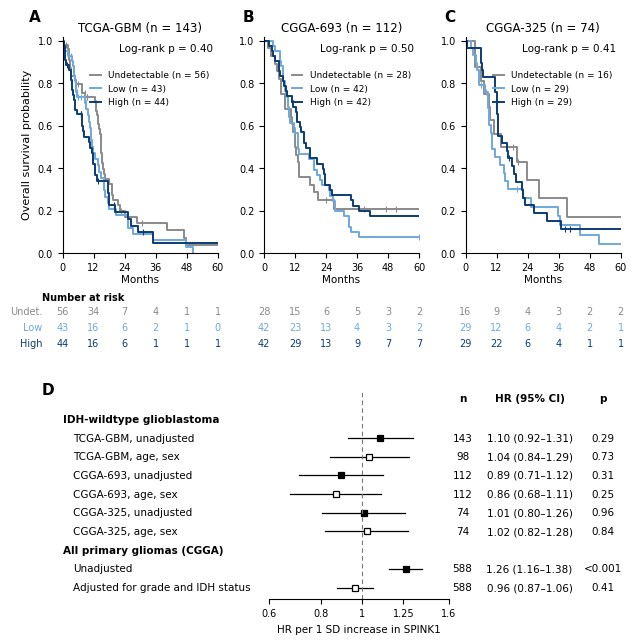

In [9]:
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
from matplotlib.ticker import NullFormatter

plt.rcParams.update({'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'DejaVu Sans'],
                     'font.size': 8, 'axes.linewidth': 0.8, 'pdf.fonttype': 42})
COLORS = {'Undetectable': '#8A8A8A', 'Low': '#6FA8DC', 'High': '#0B3C73'}
TICKS = [0, 12, 24, 36, 48, 60]

fig = plt.figure(figsize=(7.2, 7.3))
gs = GridSpec(4, 3, height_ratios=[3.0, 1.15, 0.1, 2.9], hspace=0.12, wspace=0.30, figure=fig)

for i, (cohort, d) in enumerate(surv.groupby('cohort', sort=False)):
    ax, risk = fig.add_subplot(gs[0, i]), fig.add_subplot(gs[1, i])
    for j, g in enumerate(GROUP_ORDER):
        s = d[d['group'] == g]
        KaplanMeierFitter().fit(s['time'], s['event'], label=f'{g} (n = {len(s)})').plot_survival_function(
            ax=ax, ci_show=False, show_censors=True, color=COLORS[g], lw=1.4,
            censor_styles={'ms': 4, 'marker': '|', 'mew': 0.8})
        for t in TICKS:
            risk.text(t, j, int((s['time'] >= t).sum()), ha='center', va='center', fontsize=7, color=COLORS[g])
        if i == 0:
            risk.text(-0.13, j, 'Undet.' if g == 'Undetectable' else g, ha='right', va='center',
                      fontsize=7, color=COLORS[g], transform=risk.get_yaxis_transform())
    p = multivariate_logrank_test(d['time'], d['group'], d['event']).p_value
    ax.text(0.97, 0.97, f'Log-rank p = {p:.2f}', transform=ax.transAxes, ha='right', va='top', fontsize=7.5)
    ax.set_title(f'{cohort} (n = {len(d)})', fontsize=8.5, pad=4)
    ax.set_xlim(0, 60)
    ax.set_ylim(0, 1.02)
    ax.set_xticks(TICKS)
    ax.set_xlabel('Months', fontsize=7.5, labelpad=1)
    ax.tick_params(labelsize=7)
    ax.set_ylabel('Overall survival probability' if i == 0 else '')
    ax.legend(loc='upper right', bbox_to_anchor=(1.0, 0.88), frameon=False, fontsize=6.5, handlelength=1.2)
    ax.spines[['top', 'right']].set_visible(False)
    ax.text(-0.22 if i == 0 else -0.14, 1.07, 'ABC'[i], transform=ax.transAxes, fontsize=11, fontweight='bold')
    risk.set_xlim(0, 60)
    risk.set_ylim(2.5, -2.7)
    risk.axis('off')
    if i == 0:
        risk.text(-0.13, -0.7, 'Number at risk', fontsize=7, fontweight='bold', ha='left',
                  transform=risk.get_yaxis_transform())

sub = GridSpecFromSubplotSpec(1, 3, subplot_spec=gs[3, :], width_ratios=[2.4, 2.1, 2.0], wspace=0.0)
ax_label, ax_plot, ax_text = [fig.add_subplot(sub[0, q]) for q in range(3)]
LABELS = {'Unadjusted': 'Unadjusted', 'Grade, IDH status': 'Adjusted for grade and IDH status'}
lines = []
for name, part in cox.groupby('set', sort=False):
    lines.append(('header', 'IDH-wildtype glioblastoma' if name == 'IDH-wildtype GBM' else 'All primary gliomas (CGGA)'))
    lines += [('row', r) for _, r in part.iterrows()]

for y, (kind, r) in enumerate(lines):
    if kind == 'header':
        ax_label.text(0, y, r, fontweight='bold', fontsize=7.5, va='center')
        continue
    label = f"{r['cohort']}, {r['model'].lower()}" if r['set'] == 'IDH-wildtype GBM' else LABELS[r['model']]
    ax_label.text(0.05, y, label, fontsize=7.5, va='center')
    ax_text.text(0.08, y, r['n'], fontsize=7.5, va='center', ha='center')
    ax_text.text(0.47, y, f"{r['HR']:.2f} ({r['CI_low']:.2f}–{r['CI_high']:.2f})", fontsize=7.5, va='center', ha='center')
    ax_text.text(0.90, y, f"{r['p']:.2f}" if r['p'] >= 0.001 else '<0.001', fontsize=7.5, va='center', ha='center')
    filled = r['model'] == 'Unadjusted'
    ax_plot.plot([r['CI_low'], r['CI_high']], [y, y], color='black', lw=0.9)
    ax_plot.plot(r['HR'], y, marker='s', ms=5, mfc='black' if filled else 'white', mec='black', mew=0.9)

for x, title in [(0.08, 'n'), (0.47, 'HR (95% CI)'), (0.90, 'p')]:
    ax_text.text(x, -1.1, title, fontsize=7.5, fontweight='bold', ha='center', va='center')
for a in (ax_label, ax_plot, ax_text):
    a.set_ylim(len(lines) - 0.4, -1.6)
for a in (ax_label, ax_text):
    a.set_xlim(0, 1)
    a.axis('off')
ax_plot.patch.set_alpha(0)
ax_plot.set_xscale('log')
ax_plot.set_xlim(0.6, 1.6)
ax_plot.set_xticks([0.6, 0.8, 1, 1.25, 1.6])
ax_plot.set_xticklabels(['0.6', '0.8', '1', '1.25', '1.6'])
ax_plot.xaxis.set_minor_formatter(NullFormatter())
ax_plot.minorticks_off()
ax_plot.axvline(1, ls=(0, (4, 3)), lw=0.8, color='#777777')
ax_plot.set_yticks([])
ax_plot.tick_params(labelsize=7)
ax_plot.set_xlabel('HR per 1 SD increase in SPINK1', fontsize=7.5)
ax_plot.spines[['top', 'right', 'left']].set_visible(False)
ax_label.text(-0.1, -1.6, 'D', fontsize=11, fontweight='bold', va='center')

for ext in ['png', 'pdf']:
    fig.savefig(os.path.join(RESULTS, f'Figure_S1_survival.{ext}'), dpi=600, bbox_inches='tight')
plt.show()